# Imports

In [1]:
import keras
import math
import datasets
import numpy as np
import transformers
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import train_test_split
import tensorflow as tf
import tqdm.notebook as tqdm
import sklearn.model_selection
import matplotlib.pyplot as plt

I0000 00:00:1791780844.241769    8051 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791780844.321618    8051 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791780846.386116    8051 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/home/maks/HW/NLP/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


In [2]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except:
        pass

E0000 00:00:1791780849.486040    8051 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


# Dataset

Load the dataset (we will be using [go_emotions](https://huggingface.co/datasets/google-research-datasets/go_emotions)). Pretokenize data or make a loader that tokenizes the sentenses as you iterate through the dataset. Implement two datasets: variable and fixed sentence length (in tokens). Don't forget to split the dataset into train and test subsets

In [3]:
dataset = datasets.load_dataset('google-research-datasets/go_emotions', name='raw', split='train', cache_dir='dataset').to_pandas()

In [4]:
emotions = [
    'admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity',
    'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear',
    'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief',
    'remorse', 'sadness', 'surprise', 'neutral'
]

In [5]:
tokenizer = transformers.AutoTokenizer.from_pretrained('gpt2', cache_dir='../gpt2_tokenizer')
tokenizer.pad_token = tokenizer.eos_token

In [6]:
dataset.iloc[dataset[emotions].sum(axis=1).argmax()]


text                    Two or three anti depressants before I told th...
id                                                                edelx9y
author                                                         Bluechimp1
subreddit                                                 benzodiazepines
link_id                                                         t3_acxq4h
parent_id                                                      t1_ede5mxn
created_utc                                                  1546801664.0
rater_id                                                               31
example_very_unclear                                                False
admiration                                                              1
amusement                                                               0
anger                                                                   0
annoyance                                                               0
approval                              

In [7]:
X = dataset['text']
y = dataset[emotions].to_numpy()
X_tokenized = [tokenizer.encode(e) for e in X]
X_lens = np.array(list(map(len, X_tokenized)))

X_train, X_val, y_train, y_val = train_test_split(
    X_tokenized, y, test_size=0.2, random_state=1, shuffle=True,
)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1435 > 1024). Running this sequence through the model will result in indexing errors


In [8]:
X_lens_argsort = np.argsort(X_lens)

In [9]:
X_lens[X_lens_argsort][-70:]

array([  56,   56,   56,   56,   58,   58,   58,   58,   58,   59,   59,
         59,   59,   59,   59,   59,   59,   63,   63,   63,   63,   63,
         63,   63,   63,   63,   63,   65,   65,   65,   65,   65,   67,
         67,   67,   67,   67,   67,   71,   71,   71,   85,   85,   85,
         93,   93,   93,   95,   95,   95,  104,  104,  104,  165,  165,
        165,  175,  175,  175,  184,  184,  184,  209,  209,  318,  318,
        318, 1435, 1435, 1435])

Text(0.5, 0, 'Длинна текста в токенах')

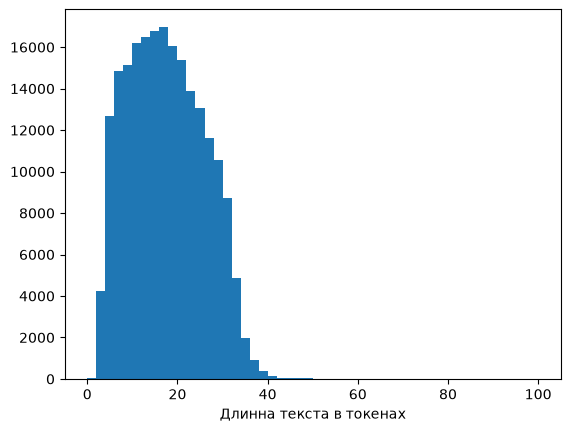

In [10]:
plt.hist(X_lens, bins=50, range=(0, 100))
plt.xlabel('Длинна текста в токенах')

In [11]:
b_size = 512
X_lens_bins = np.array_split(X_lens[X_lens_argsort], -(-len(X_lens) // b_size))
y_bins = np.array_split(y[X_lens_argsort], -(-len(X_lens) // b_size))
X_lens_bins

[array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
        3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 

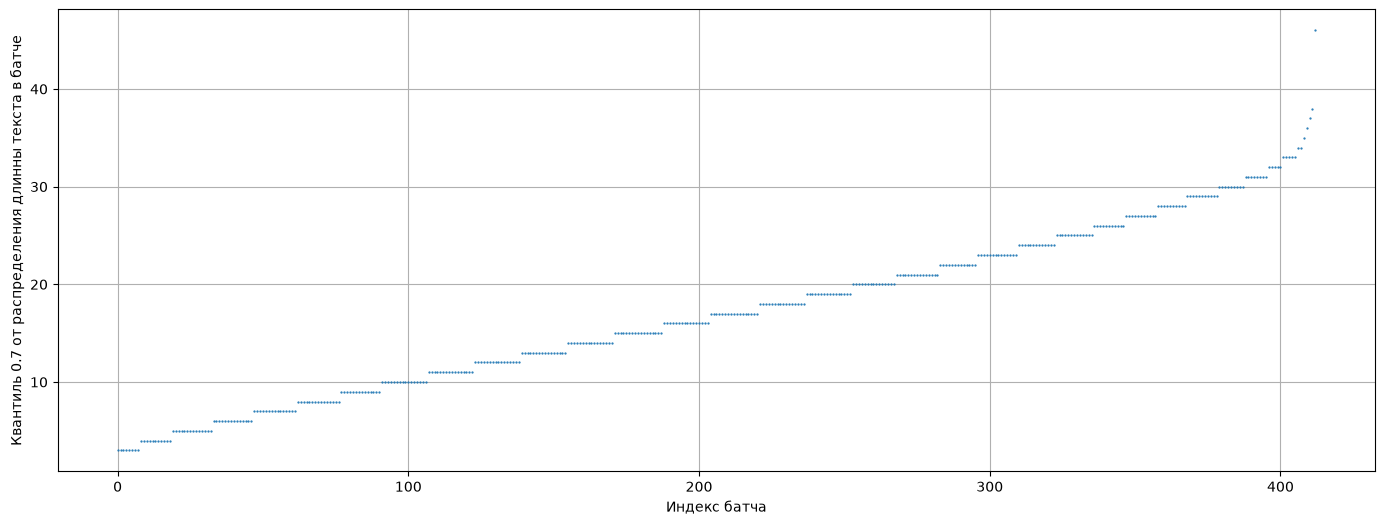

In [12]:
q = 0.7

plt.figure(figsize=(17, 6))
plt.plot([np.quantile(e, q) for e in X_lens_bins], linestyle=' ', marker='o', markersize=0.6)
plt.xlabel('Индекс батча')
plt.ylabel(f'Квантиль {q} от распределения длинны текста в батче')
plt.grid()

In [13]:
y_bins_sum = [b.sum(axis=0) for b in y_bins]
y_bins_sum

[array([ 45,   8,  18,  16,  27,   3,   8,  16,   2,   6,   9,   6,   1,
         24,   2,  59,   2,  19,  13,   2,   6,   0,   5,   1,   2,   9,
         16, 189]),
 array([ 60,  15,  21,  16,  34,   9,   5,  11,   1,  15,   7,  12,   1,
         17,   7,  51,   0,  18,  21,   3,   7,   1,   8,   2,   3,  17,
          7, 164]),
 array([ 63,  15,  24,  16,  34,   6,   6,  11,   2,   5,   4,   9,   2,
         20,  10,  64,   3,  13,  22,   1,   4,   5,   6,   0,   1,   3,
         14, 164]),
 array([ 59,  13,  24,  20,  25,  11,  10,   8,   3,   8,  12,  11,   4,
         16,   7,  39,   1,  23,  29,   1,   7,   1,   3,   2,   2,  13,
          7, 157]),
 array([ 61,  14,  21,  17,  31,   8,   9,   9,   3,   8,   7,   6,   5,
         18,   6,  50,   0,  16,  20,   3,   5,   1,   3,   1,   2,  19,
         12, 165]),
 array([ 57,   9,  19,  10,  29,  11,   8,  11,   1,  11,   9,   9,   0,
         15,   9,  68,   0,  14,  27,   0,   7,   5,   5,   0,   5,  10,
         12, 159]),
 arr

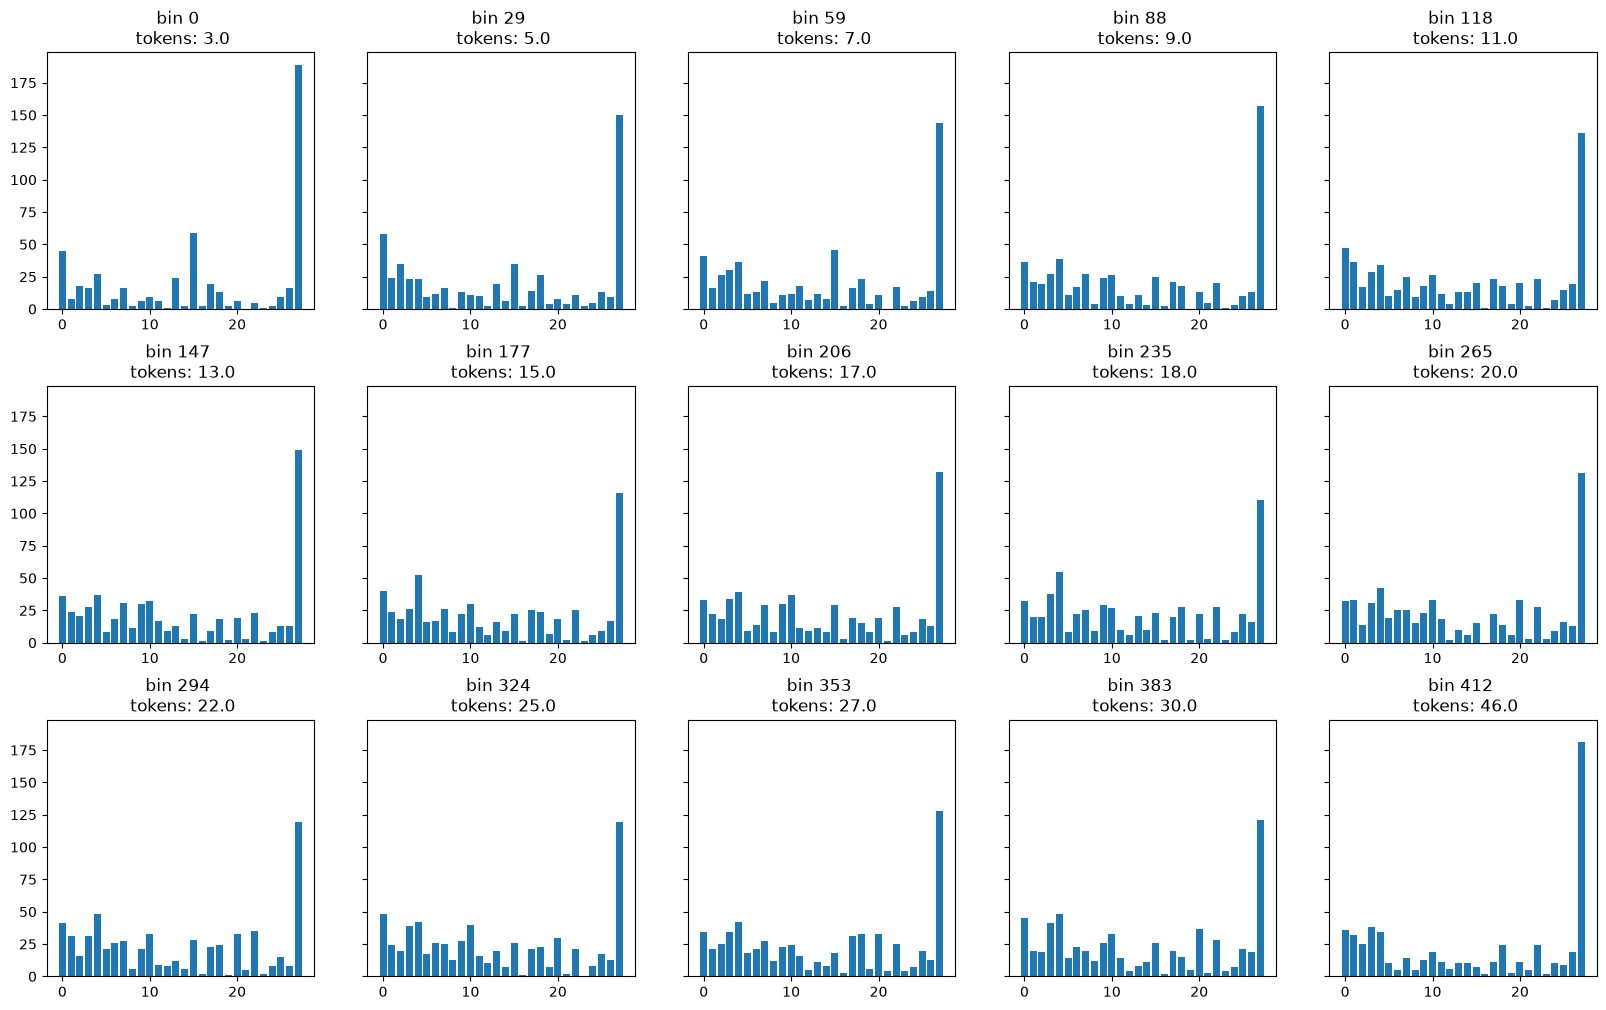

In [14]:
n_graphs = 15
n_cols = 5
q = 0.7
n_rows = int(np.ceil(n_graphs / n_cols))

fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=(4 * n_cols, 4 * n_rows),
                         sharey=True, )
idx = np.linspace(0, len(y_bins_sum) - 1, n_graphs).round().astype(int)
axes = axes.flatten()

for ax, i in zip(axes, idx):
    ax.bar(range(len(emotions)), y_bins_sum[i])
    ax.set_title(f"bin {i} \n tokens: {np.quantile(X_lens_bins[i], q)}")
fig.subplots_adjust(hspace=0.3)

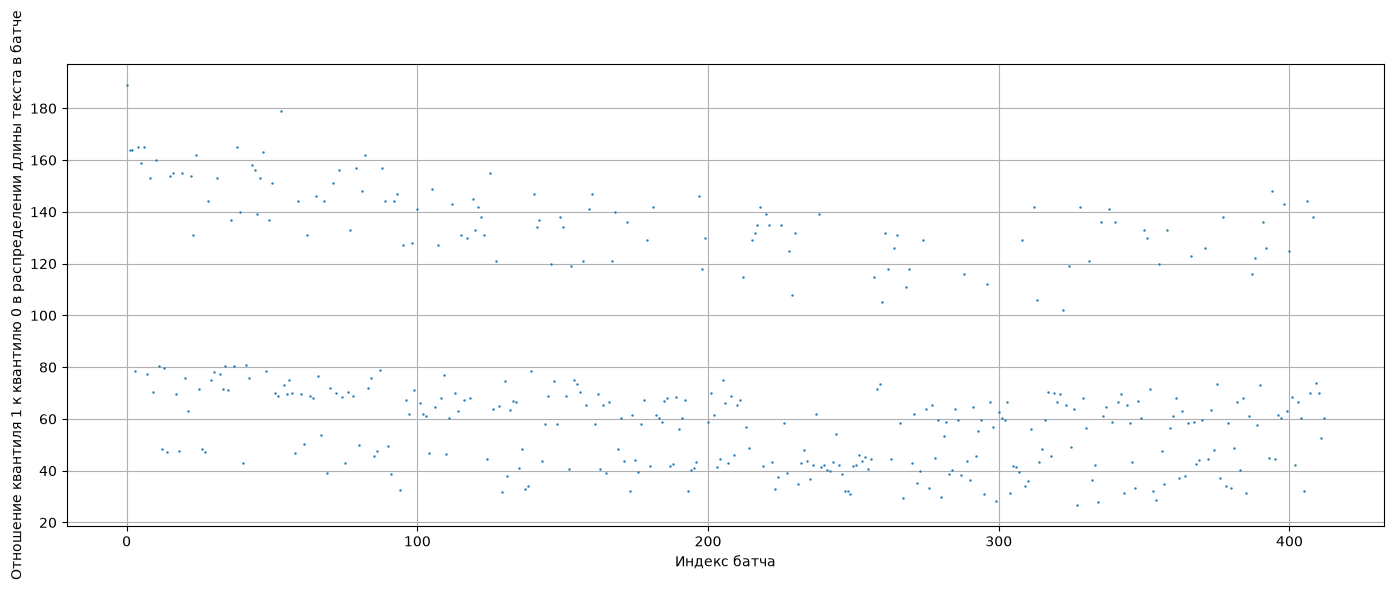

In [15]:
q = 1
y_bins_sum = [e.sum(axis=0) for e in y_bins]
y_bins_diff = [np.quantile(e, q) / (np.quantile(e, 1 - q) + 1) for e in y_bins_sum]

plt.figure(figsize=(17, 6))
plt.plot(y_bins_diff, linestyle=' ', marker='o', markersize=0.7)
plt.xlabel('Индекс батча')
plt.ylabel(f'Отношение квантиля {q} к квантилю {1 - q} в распределении длины текста в батче')
plt.grid()

In [16]:
class SmartBatchDataset(keras.utils.PyDataset):
    def __init__(self, X, y, batch_size=64, q=0.5, seed=1, shuffle=False, **kwargs):
        super().__init__(**kwargs)
        self.X = X
        self.y = y
        self.batch_size = batch_size
        self.q = q
        self.rng = np.random.default_rng(seed=seed)
        self.shuffle = shuffle

        X_lens = np.array(list(map(len, self.X)), dtype='int32')
        idx_sorted = np.argsort(X_lens)

        self.X = [self.X[i] for i in idx_sorted]
        self.y = [self.y[i] for i in idx_sorted]
        X_lens = X_lens[idx_sorted]

        self.X = [self.X[i * batch_size: (i + 1) * batch_size] for i in range(-(-len(self.X) // batch_size))]
        self.y = [np.array(self.y[i * batch_size: (i + 1) * batch_size]) for i in range(-(-len(self.y) // batch_size))]
        X_lens = [X_lens[i * batch_size: (i + 1) * batch_size] for i in range(-(-len(X_lens) // batch_size))]

        for i in range(len(self.X)):            
            self.X[i] = keras.utils.pad_sequences(
                self.X[i], 
                maxlen=math.ceil(np.quantile(X_lens[i], self.q)),
                padding='post',
                truncating='post',
                value=tokenizer.pad_token_id
            )

        self.shuffle_batch_idx = np.arange(len(self.X))

        self.on_epoch_end()

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return (
            self.X[self.shuffle_batch_idx[idx]], 
            self.y[self.shuffle_batch_idx[idx]]
        )

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.shuffle_batch_idx)

In [17]:
class DefaultBatchDataset(keras.utils.PyDataset):
    def __init__(self, X, y, batch_size=64, q=0.5, seed=1, shuffle=False, **kwargs):
        super().__init__(**kwargs)
        self.X = X
        self.y = np.array(y)
        self.batch_size = batch_size
        self.q = q
        self.rng = np.random.default_rng(seed=seed)
        self.shuffle = shuffle

        self.X_lens = np.array(list(map(len, self.X)), dtype='int32')

        self.idxs = np.arange(len(self.X))

    def __len__(self):
        return -(-len(self.X) // self.batch_size)

    def __getitem__(self, idx):
        ind = self.idxs[idx * self.batch_size: (idx + 1) * self.batch_size]
        return keras.utils.pad_sequences(
            [self.X[i] for i in ind], 
            maxlen=math.ceil(np.quantile(self.X_lens[ind], self.q)),
            padding='post',
            truncating='post',
            value=tokenizer.pad_token_id
        ), self.y[ind]

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.idxs)


# Model

Implement your model. The model should have the RNN architecture (with LSTM or GRU cells), support stacking and bidirectional feature extraction.

In [18]:
def get_name(prefix: str | None = None, suffix: str | None = None, separator: str = '_') -> str | None:
    return prefix and prefix + separator + suffix or suffix or None

In [19]:
def get_model(
    units: int,
    n_tokens: int,
    n_labels: int,
    n_stacks: int = 1,
    bidirectional: bool = False,
    name: str | None = None,
    cell_type: type[keras.layers.Layer] = keras.layers.LSTMCell,
    *,
    embed_size: int = 128
) -> keras.Model:
    '''Creates a model with RNN architecture for sequence multilabel classification.

    Arguments:
        units: dimensionality of RNN cells
        n_tokens: number of tokens in the tokenizer dictionary
        n_labels: number of labels to be predicted
        n_stacks: number of RNN cells in the stack (1 -- no stacking)
        bidirectional: whether or not the model is bidirectional
        name: the model name
        cell_type: type of a cell to use, either keras.layers.LSTMCell or keras.layers.GRUCell

    Returns:
        The model'''

    if cell_type is keras.layers.LSTMCell:
        rnn = keras.layers.LSTM
    else:
        rnn = keras.layers.GRU

    inputs = x = keras.layers.Input(shape=(None,), name='Input', dtype='int32')
    x = keras.layers.Embedding(n_tokens, embed_size, name='Embedding')(x)

    for i in range(n_stacks):
        is_not_last = i != n_stacks - 1

        if bidirectional:
            x = keras.layers.Bidirectional(rnn(units=units, return_sequences=is_not_last), name=f'RNN_{i}')(x)
        else:
            x = rnn(units=units, return_sequences=is_not_last, name=f'RNN_{i}')(x)

    output = keras.layers.Dense(n_labels, name='output')(x)
    
    return keras.models.Model(inputs=inputs, outputs=output, name=name)

# Training

Train several models on the two dataset variants. Use either of the cell types (LSTM or GRU)
* Simple RNN (no stacking, one direction)
* Stacked RNN (stacking, one direction)
* Bidirectional RNN (no stacking, bidirectional)
* Stacked Bidirectional RNN (stacking, bidirectional)

In [20]:
models = [
    get_model(
        units=128,
        n_tokens=len(tokenizer.get_vocab()),
        n_labels=len(emotions),
        name='LSTM_model',
        bidirectional=i[1],
        n_stacks=i[0],
        cell_type=keras.layers.LSTMCell,
        embed_size=128
    )
    for i in [(1, False), (2, False), (1, True), (2, True), (1, False), (2, False), (1, True), (2, True)]
]

In [21]:
models[3].summary()

Model: "LSTM_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input (InputLayer)              │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Embedding (Embedding)           │ (None, None, 128)      │     6,432,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ RNN_0 (Bidirectional)           │ (None, None, 256)      │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ RNN_1 (Bidirectional)           │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 28)             │         7,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,097,500 (27.07 MB)

 Trainable params: 7,097,500 (27.07 MB)

 Non-trainable params: 0 (0.00 B)

Which loss should be used to multilabel classification? Which metrics?

In [22]:
@keras.saving.register_keras_serializable()
class WeightedBCE(keras.losses.Loss):
    def __init__(self, w, from_logits=True, name="weighted_bce", **kwargs):
        super().__init__(name=name, **kwargs)
        self.w = w
        self.from_logits = from_logits

    def call(self, y_true, y_pred):
        bce = keras.ops.binary_crossentropy(
            y_true, y_pred, from_logits=self.from_logits
        )

        w = keras.ops.convert_to_tensor(self.w, dtype=bce.dtype)
        w = keras.ops.reshape(w, (1, -1))
        w = keras.ops.where(
            keras.ops.equal(y_true, 1.0),
            w,
            keras.ops.ones_like(bce),
        )

        return keras.ops.mean(bce * w, axis=-1)

    def get_config(self):
        config = super().get_config()
        config.update({
            'w': self.w,
            'from_logits': self.from_logits,
        })
        return config

In [23]:
w = y.sum(axis=0)
w = 1 / w
w /= w.min()
w = np.clip(w, 1.0, 100.0)
w

array([ 3.22794933,  5.98139535,  6.84042553,  4.06065502,  3.13836549,
        9.21786964,  7.51433619,  5.70553033, 14.48729369,  6.52946038,
        4.8405112 , 10.43161668, 22.33360258,  9.82376976, 17.29684079,
        4.7568172 , 82.16641902,  6.92696981,  6.75106825, 30.55138122,
        6.34515204, 42.47158218,  6.29459306, 42.89992242, 21.90019802,
        8.1825984 , 10.02865433,  1.        ])

In [24]:
class SigmoidAUC(keras.metrics.AUC):
    def update_state(self, y_true, y_pred, sample_weight=None):
        return super().update_state(y_true, keras.ops.sigmoid(y_pred), sample_weight)

class SigmoidF1(keras.metrics.F1Score):
    def update_state(self, y_true, y_pred, sample_weight=None):
        return super().update_state(y_true, keras.ops.sigmoid(y_pred), sample_weight)

In [25]:
for model in models:
    model.compile(
        loss=WeightedBCE(w, from_logits=True),
        optimizer=keras.optimizers.Adam(
            clipnorm=1.0
        ),
        metrics=[
            keras.metrics.AUC(multi_label=True, num_labels=len(emotions)),
            keras.metrics.F1Score(average='macro'),
        ]
    )

In [26]:
smart_dataset = SmartBatchDataset(X_train, y_train, batch_size=200, q=0.8, shuffle=True)
default_dataset = DefaultBatchDataset(X_train, y_train, batch_size=200, q=0.8, shuffle=True)
val_dataset = DefaultBatchDataset(X_val, y_val, batch_size=200, q=0.8, shuffle=False)

In [27]:
def make_callbacks(name):
    return [
        keras.callbacks.ModelCheckpoint(f'{name}.keras', monitor='val_loss',
                                  save_best_only=True),
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=10,
                                restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                    patience=5, min_lr=1e-6),
    ]

In [28]:
epochs = 10

models[0].fit(smart_dataset, validation_data=val_dataset, epochs=epochs, callbacks=make_callbacks('LSTM_smart_st1_nonbi'))
models[1].fit(smart_dataset, validation_data=val_dataset, epochs=epochs, callbacks=make_callbacks('LSTM_smart_st2_nonbi'))
models[2].fit(smart_dataset, validation_data=val_dataset, epochs=epochs, callbacks=make_callbacks('LSTM_smart_st1_bi'))
models[3].fit(smart_dataset, validation_data=val_dataset, epochs=epochs, callbacks=make_callbacks('LSTM_smart_st2_bi'))
models[4].fit(default_dataset, validation_data=val_dataset, epochs=epochs, callbacks=make_callbacks('LSTM_default_st1_nonbi'))
models[5].fit(default_dataset, validation_data=val_dataset, epochs=epochs, callbacks=make_callbacks('LSTM_default_st2_nonbi'))
models[6].fit(default_dataset, validation_data=val_dataset, epochs=epochs, callbacks=make_callbacks('LSTM_default_st1_bi'))
models[7].fit(default_dataset, validation_data=val_dataset, epochs=epochs, callbacks=make_callbacks('LSTM_default_st2_bi'))

Epoch 1/10


I0000 00:00:1791718830.231025  126311 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


845/845 ━━━━━━━━━━━━━━━━━━━━ 78s 91ms/step - auc: 0.5517 - f1_score: 0.1172 - loss: 0.5751 - val_auc: 0.6252 - val_f1_score: 0.1667 - val_loss: 0.5253 - learning_rate: 0.0010
Epoch 2/10
845/845 ━━━━━━━━━━━━━━━━━━━━ 76s 89ms/step - auc: 0.6866 - f1_score: 0.2534 - loss: 0.4512 - val_auc: 0.6494 - val_f1_score: 0.2326 - val_loss: 0.5073 - learning_rate: 0.0010
Epoch 3/10
845/845 ━━━━━━━━━━━━━━━━━━━━ 77s 91ms/step - auc: 0.7407 - f1_score: 0.3096 - loss: 0.3949 - val_auc: 0.6842 - val_f1_score: 0.2854 - val_loss: 0.4663 - learning_rate: 0.0010
Epoch 4/10
845/845 ━━━━━━━━━━━━━━━━━━━━ 76s 90ms/step - auc: 0.7773 - f1_score: 0.3451 - loss: 0.3506 - val_auc: 0.7042 - val_f1_score: 0.2880 - val_loss: 0.4693 - learning_rate: 0.0010
Epoch 5/10
845/845 ━━━━━━━━━━━━━━━━━━━━ 75s 89ms/step - auc: 0.8046 - f1_score: 0.3698 - loss: 0.3165 - val_auc: 0.6945 - val_f1_score: 0.2854 - val_loss: 0.5106 - learning_rate: 0.0010
Epoch 6/10
845/845 ━━━━━━━━━━━━━━━━━━━━ 75s 89ms/step - auc: 0.8256 - f1_score: 0

In [28]:
models = [
    keras.models.load_model('LSTM_smart_st1_nonbi.keras'),
    keras.models.load_model('LSTM_smart_st2_nonbi.keras'),
    keras.models.load_model('LSTM_smart_st1_bi.keras'),
    keras.models.load_model('LSTM_smart_st2_bi.keras'),
    keras.models.load_model('LSTM_default_st1_nonbi.keras'),
    keras.models.load_model('LSTM_default_st2_nonbi.keras'),
    keras.models.load_model('LSTM_default_st1_bi.keras'),
    keras.models.load_model('LSTM_default_st2_bi.keras')
]

/home/maks/HW/NLP/.venv/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_17', because it has 14 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)
/home/maks/HW/NLP/.venv/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_18', because it has 20 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)
/home/maks/HW/NLP/.venv/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_19', because it has 20 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)
/home/maks/HW/NLP/.venv/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam_20', because it has 32 variables whereas the saved optimizer

# Evaluation

Evaluate the models you trained on the test datasets. Plot ROC curves for each label (use `sklearn.metrics.RocCurveDisplay`) for each model.

In [71]:
def plot_roc_curve(
    X: keras.utils.PyDataset | np.ndarray,
    y: np.ndarray,
    model: keras.Model,
    ax: plt.Axes | None = None,
    is_leg=False
) -> float:
    '''Plots ROC curves for each of the labels (on a single axes) and outputs mean ROC AUC score.

    Arguments:
        X: model inputs
        y: ground thruths
        model: model to plot the curve for
        ax: axes to plot on

    Returns:
        Mean ROC AUC score'''
    fprs = [0] * len(emotions)
    tprs = [0] * len(emotions)
    aucs = [0] * len(emotions)

    if issubclass(type(X), keras.utils.PyDataset):
        y = []
        pred = []
        for x_, y_ in X:
            pred.append(np.array(keras.ops.sigmoid(model(x_))))
            y.append(y_)

        pred = np.concatenate([p.reshape(-1, p.shape[-1]) for p in pred], axis=0)

        y = np.concatenate(y, axis=0)
    else:
        pred = np.array(keras.ops.sigmoid(model(X))).reshape(-1, len(emotions))

    for i in range(len(emotions)):
        fprs[i], tprs[i], _ = roc_curve(y[:, i], pred[:, i])
        aucs[i] = auc(fprs[i], tprs[i])

        ax.plot(fprs[i], tprs[i], label=emotions[i])

    leg = ax.get_legend_handles_labels()
    if is_leg:
        return np.nanmean(aucs), leg

    return np.nanmean(aucs)

np.float64(0.8323307662603259)

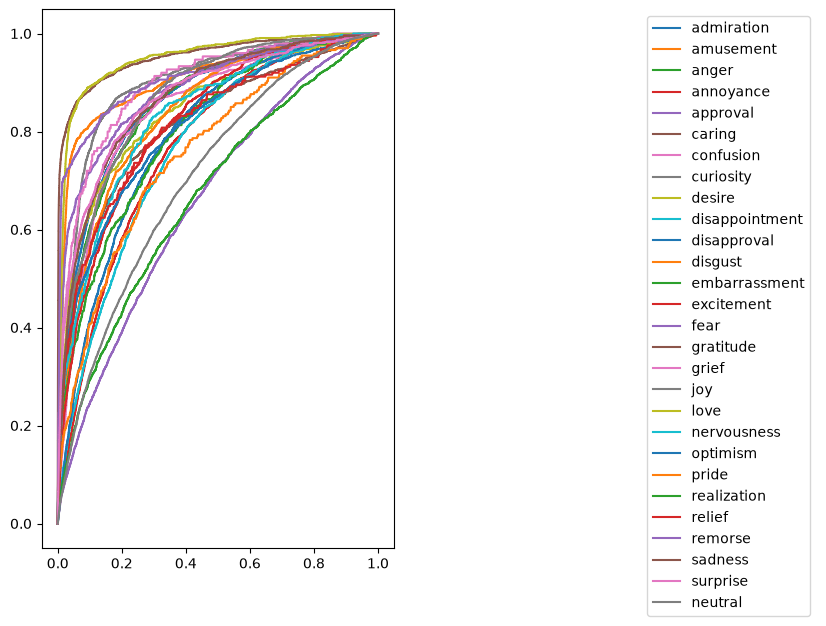

In [68]:
fig, ax = plt.subplots(1, 2, figsize=(10, 7))

a, leg = plot_roc_curve(val_dataset, None, models[0], ax=ax[0], is_leg=True)
ax[1].axis('off')
ax[1].legend(*leg)

a

Plot the mean ROC AUC scores. Which model has the highest score? On what kind of dataset?

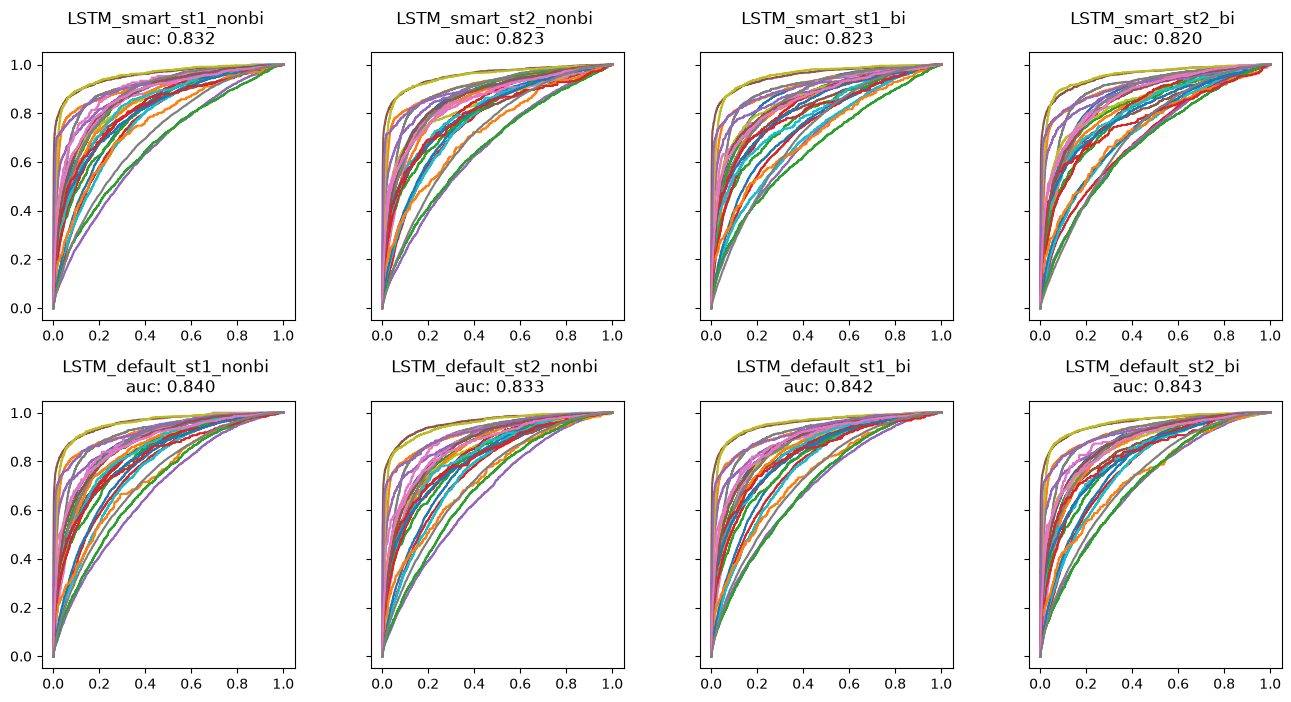

In [ ]:
names = [
    'LSTM_smart_st1_nonbi',
    'LSTM_smart_st2_nonbi',
    'LSTM_smart_st1_bi',
    'LSTM_smart_st2_bi',
    'LSTM_default_st1_nonbi',
    'LSTM_default_st2_nonbi',
    'LSTM_default_st1_bi',
    'LSTM_default_st2_bi',
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharey=True)

for i in range(2):
    for j in range(4):
        score = plot_roc_curve(val_dataset, None, models[i * 4 + j], axes[i, j])
        axes[i, j].set_title(f'{names[i * 4 + j]} \n auc: {score:.3f}')

fig.subplots_adjust(hspace=0.3, wspace=0.3)

Inspect the best model performance closer. Come up with some sentences (in English). Does the model output sensible results?

In [47]:
def label_text(text: str, model: keras.Model, threshold: float = 0.5, max_length: int | None = None) -> list[str]:
    '''Computes the model output for `text` and outputs a list of emotions that have a probability of at least `threshold`

    Arguments:
        text: text to label
        model: model to use
        threshold: threshold to use
        max_length: max length for tokenization
    
    Return:
        List of predicted emotion labels'''

    tokens = np.array(tokenizer.encode(text, max_length=max_length), dtype='int32').reshape(1, -1)
    pred = np.array(keras.ops.sigmoid(model(tokens))).ravel()
    e = []

    for i, em in enumerate(emotions):
        if pred[i] >= threshold:
            e.append(em)

    return e


In [32]:
label_text('this is a simple text. I hate !!!!!!!. AAAAAAaaaAAAaAAAA. i want to eat. its fun', models[6])

['amusement', 'anger', 'annoyance', 'joy']

In [33]:
def plot_emotion_scores(text: str, model: keras.Model, max_length: int | None = None, ax: plt.Axes | None = None):
    '''Plots a bar plot of emotion probabilities for given `text` using `model`.

    Arguments:
        text: text to label
        model: model to use        
        max_length: max length for tokenization
        ax: axes to plot on'''
    tokens = np.array(tokenizer.encode(text, max_length=max_length), dtype='int32')[None]
    pred = np.array(keras.ops.sigmoid(model(tokens))).ravel()

    ax.bar(emotions, pred)

For each of your texts get a list of emotion labels and plot emotion scores

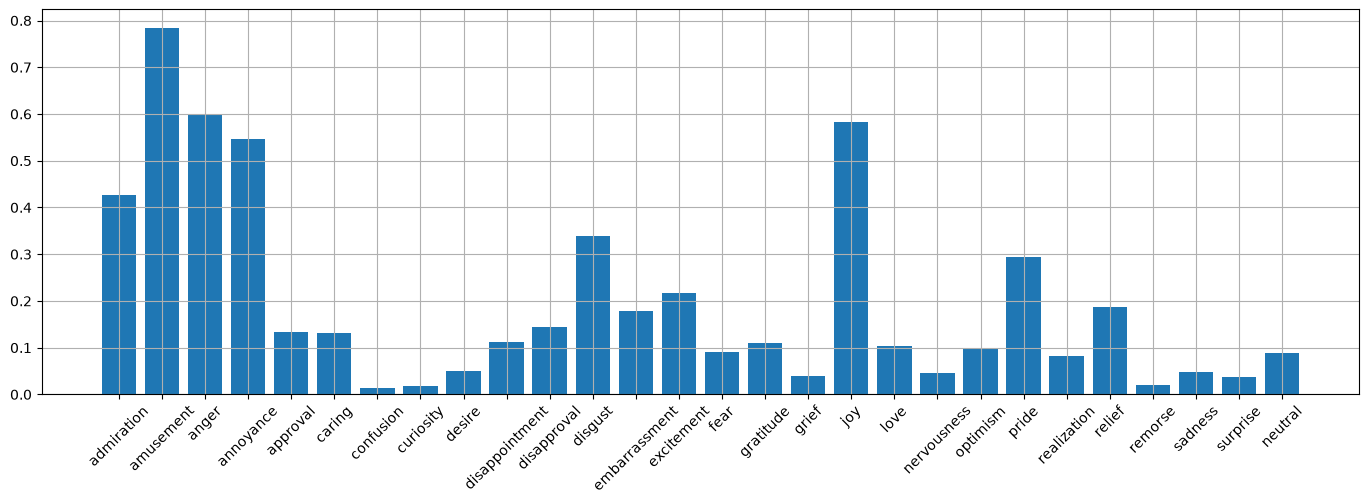

In [34]:
fig, ax = plt.subplots(1, 1, figsize=(17, 5))

plot_emotion_scores('this is a simple text. I hate !!!!!!!. AAAAAAaaaAAAaAAAA. i want to eat. its fun', models[6], ax=ax)
ax.tick_params(axis='x', rotation=45)
ax.grid()

# Bonus

Train and evaluate the same model as your best one, but use a different cell type

In [35]:
model_gru = get_model(
    units=128,
    n_tokens=len(tokenizer.get_vocab()),
    n_labels=len(emotions),
    name='GRU_model',
    bidirectional=True,
    n_stacks=1,
    cell_type=keras.layers.GRUCell,
    embed_size=128
)

model_gru.compile(
    loss=WeightedBCE(w, from_logits=True),
    optimizer=keras.optimizers.Adam(
        clipnorm=1.0
    ),
    metrics=[
        keras.metrics.AUC(multi_label=True, num_labels=len(emotions)),
        keras.metrics.F1Score(average='macro'),
    ]
)

In [40]:
model_gru.fit(default_dataset, validation_data=val_dataset, epochs=10, callbacks=make_callbacks('GRU_default_st1_bi'))

Epoch 1/10


I0000 00:00:1791775576.390192    5646 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


845/845 ━━━━━━━━━━━━━━━━━━━━ 115s 133ms/step - auc_9: 0.6097 - f1_score: 0.1931 - loss: 0.5252 - val_auc_9: 0.6924 - val_f1_score: 0.2691 - val_loss: 0.4576 - learning_rate: 0.0010
Epoch 2/10
845/845 ━━━━━━━━━━━━━━━━━━━━ 109s 129ms/step - auc_9: 0.7184 - f1_score: 0.3005 - loss: 0.4181 - val_auc_9: 0.7192 - val_f1_score: 0.2967 - val_loss: 0.4325 - learning_rate: 0.0010
Epoch 3/10
845/845 ━━━━━━━━━━━━━━━━━━━━ 109s 129ms/step - auc_9: 0.7599 - f1_score: 0.3367 - loss: 0.3707 - val_auc_9: 0.7284 - val_f1_score: 0.3034 - val_loss: 0.4383 - learning_rate: 0.0010
Epoch 4/10
845/845 ━━━━━━━━━━━━━━━━━━━━ 109s 129ms/step - auc_9: 0.7940 - f1_score: 0.3623 - loss: 0.3307 - val_auc_9: 0.7253 - val_f1_score: 0.3001 - val_loss: 0.4622 - learning_rate: 0.0010
Epoch 5/10
845/845 ━━━━━━━━━━━━━━━━━━━━ 109s 129ms/step - auc_9: 0.8199 - f1_score: 0.3831 - loss: 0.2979 - val_auc_9: 0.7215 - val_f1_score: 0.2966 - val_loss: 0.5016 - learning_rate: 0.0010
Epoch 6/10
845/845 ━━━━━━━━━━━━━━━━━━━━ 111s 131ms/

In [45]:
model_gru = keras.models.load_model('GRU_default_st1_bi.keras')

In [69]:
txt = 'this is a simple text. I hate !!!!!!!. AAAAAAaaaAAAaAAAA. i want to eat. its fun'
print(label_text(txt, model_gru))

['amusement', 'anger', 'disgust', 'excitement', 'joy']


0.8475365970238278


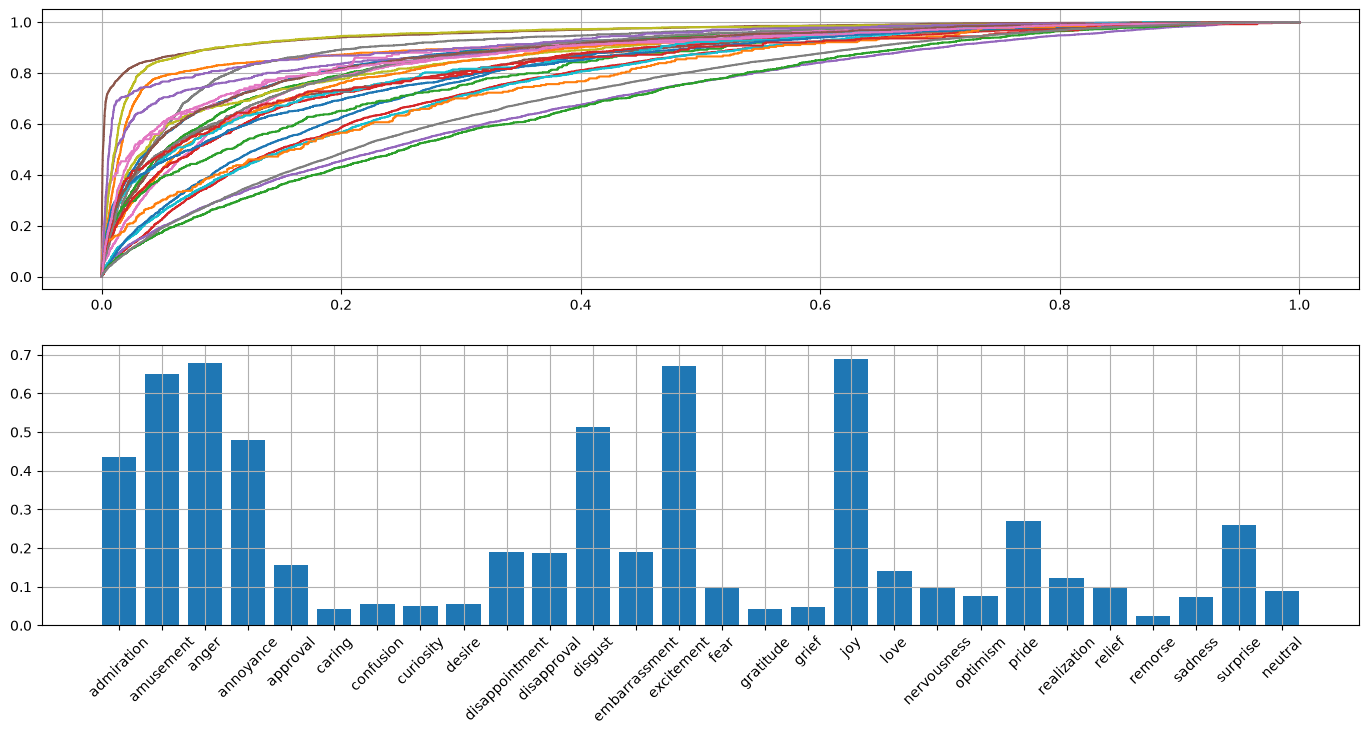

In [55]:
fig, ax = plt.subplots(2, 1, figsize=(17, 8))

t = tokenizer.encode(txt)

print(plot_roc_curve(val_dataset, None, model_gru, ax[0]))
plot_emotion_scores(txt, model_gru, ax=ax[1])

ax[1].tick_params(axis='x', rotation=45)
ax[0].grid()
ax[1].grid()